# BankSim — Graf Tabanlı Öznitelik Mühendisliği

## Öznitelik setleri

- **Set A** (8): ham işlem öznitelikleri
- **Set B** (20): A + davranışsal aggregate'ler
- **Set C** (33): B + graf öznitelikleri
- **Set D** (21): A + graf öznitelikleri — *graf katkısını aggregate'lerden izole eder*

## 1. Kurulum ve Yapılandırma

In [26]:
# pip install pandas numpy networkx python-louvain scikit-learn xgboost lightgbm imbalanced-learn shap scipy matplotlib seaborn

import pandas as pd, numpy as np, networkx as nx
import time, warnings, gc, json, os
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
from community import community_louvain
from scipy import stats

from sklearn.model_selection import StratifiedKFold, GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef,
                             confusion_matrix, precision_recall_curve, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek

warnings.filterwarnings('ignore')

# ============ YAPILANDIRMA ============
SEED = 42
N_FOLDS = 5
BETWEENNESS_K = 300     # betweenness örnekleme boyutu
TEMPORAL_CUT = 144      # step <= 144 eğitim, > 144 test (%80/%20)

# Hız/tamlık dengesi
#   SUBSAMPLE_N=200000 + FAST_MODE=True  -> ~1.5 saat (ilk deneme)
#   SUBSAMPLE_N=None   + FAST_MODE=True  -> ~4 saat   (ara sonuç)
#   SUBSAMPLE_N=None   + FAST_MODE=False -> ~7 saat   (nihai sonuç)
FAST_MODE = True
SUBSAMPLE_N = None    # None -> tam veri

KNN_TRAIN_CAP = 50000   # KNN kuadratik olceklenir; egitim seti sinirlanir
SAMPLING_FOLDS = 3      # sinif dengeleme bolumunde kullanilacak fold sayisi

# ============ CHECKPOINT (Colab kopmalarina karsi) ============
CHECKPOINT_DIR = 'checkpoints'
RESUME = True           # True: onceki calistirmadan kalinan yerden devam

# Colab'da Drive'a kaydetmek icin asagidaki iki satiri acin:
# from google.colab import drive; drive.mount('/content/drive')
# CHECKPOINT_DIR = '/content/drive/MyDrive/fraud_checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
np.random.seed(SEED)
print(f'FAST_MODE={FAST_MODE}  SUBSAMPLE_N={SUBSAMPLE_N}  N_FOLDS={N_FOLDS}')
print(f'CHECKPOINT_DIR={CHECKPOINT_DIR}  RESUME={RESUME}')

FAST_MODE=True  SUBSAMPLE_N=None  N_FOLDS=5
CHECKPOINT_DIR=checkpoints  RESUME=True


## 2. Veri Yükleme ve Keşifsel Analiz

In [27]:
df = pd.read_csv('bs140513_032310.csv')
print(f'Ham okuma: {len(df):,} satır')

# --- VERİ BÜTÜNLÜĞÜ KONTROLÜ ---
CRITICAL = ['step','customer','merchant','category','amount','fraud']
nan_counts = df[CRITICAL].isna().sum()
if nan_counts.sum() > 0:
    print('UYARI — eksik değer bulundu:')
    print(nan_counts[nan_counts > 0].to_string())
    before = len(df)
    df = df.dropna(subset=CRITICAL).copy()
    print(f'Temizlendi: {before:,} -> {len(df):,} satır')

df['fraud']  = pd.to_numeric(df['fraud'],  errors='coerce').astype(int)
df['step']   = pd.to_numeric(df['step'],   errors='coerce').astype(int)
df['amount'] = pd.to_numeric(df['amount'], errors='coerce')
df = df.dropna(subset=['amount']).reset_index(drop=True)
assert df['fraud'].isna().sum() == 0 and set(df['fraud'].unique()) <= {0,1}

# BankSim CSV'sinde değerler tek tırnak içinde geliyor
for c in ['customer','age','gender','zipcodeOri','merchant','zipMerchant','category']:
    df[c] = df[c].astype(str).str.strip("'")

df['customer_node'] = 'C_' + df['customer']
df['merchant_node'] = 'M_' + df['merchant']
df['amount_log'] = np.log1p(df['amount'])

if SUBSAMPLE_N:
    fr = df[df['fraud']==1]
    nm = df[df['fraud']==0].sample(min(SUBSAMPLE_N-len(fr), (df['fraud']==0).sum()), random_state=SEED)
    df = pd.concat([fr,nm]).sort_values('step').reset_index(drop=True)
    print(f'ALT ÖRNEKLEM aktif: {len(df):,} satır')

print(f'İşlem sayısı      : {len(df):,}')
print(f'Müşteri / Merchant: {df["customer"].nunique():,} / {df["merchant"].nunique()}')
print(f'Zaman adımı       : {df["step"].min()} - {df["step"].max()}')
print(f'Fraud             : {df["fraud"].sum():,} (%{df["fraud"].mean()*100:.3f})')
print(f'Dengesizlik oranı : 1:{int((df["fraud"]==0).sum()/df["fraud"].sum())}')
print()
print('Zamansal bölme kontrolü:')
for lab, mask in [('Eğitim (step<=144)', df['step']<=TEMPORAL_CUT),
                  ('Test  (step >144)', df['step']>TEMPORAL_CUT)]:
    sub = df[mask]
    print(f'  {lab}: n={len(sub):,}  fraud={sub["fraud"].sum():,} (%{sub["fraud"].mean()*100:.3f})')

Ham okuma: 594,643 satır
İşlem sayısı      : 594,643
Müşteri / Merchant: 4,112 / 50
Zaman adımı       : 0 - 179
Fraud             : 7,200 (%1.211)
Dengesizlik oranı : 1:81

Zamansal bölme kontrolü:
  Eğitim (step<=144): n=465,094  fraud=5,800 (%1.247)
  Test  (step >144): n=129,549  fraud=1,400 (%1.081)


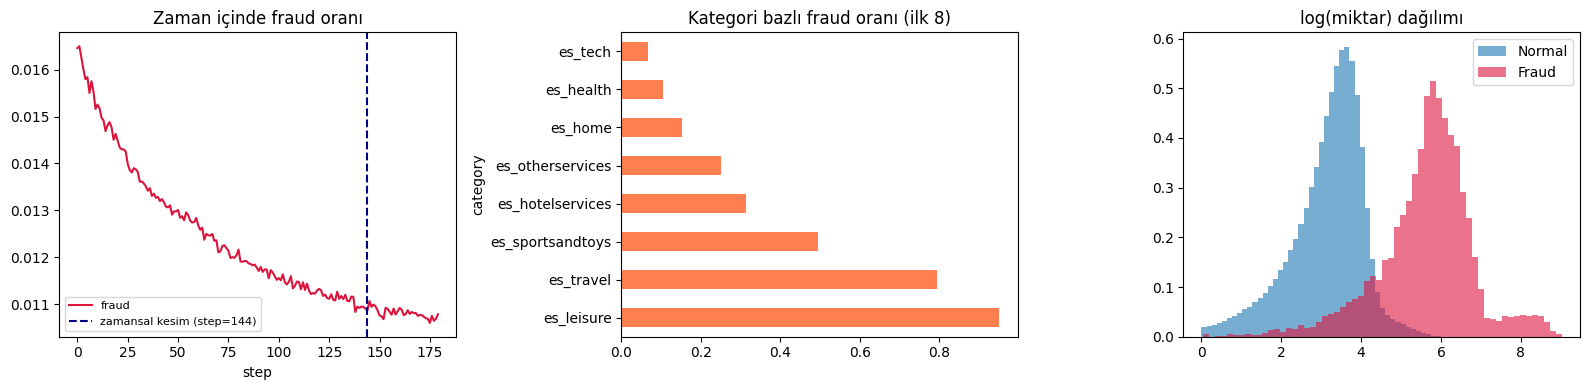

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16,4))

df.groupby('step')['fraud'].mean().plot(ax=ax[0], color='crimson')
ax[0].axvline(TEMPORAL_CUT, ls='--', color='navy', label=f'zamansal kesim (step={TEMPORAL_CUT})')
ax[0].set_title('Zaman içinde fraud oranı'); ax[0].set_xlabel('step'); ax[0].legend(fontsize=8)

cat_fr = df.groupby('category')['fraud'].mean().sort_values(ascending=False).head(8)
cat_fr.plot(kind='barh', ax=ax[1], color='coral')
ax[1].set_title('Kategori bazlı fraud oranı (ilk 8)')

ax[2].hist(df.loc[df.fraud==0,'amount_log'], bins=60, alpha=.6, label='Normal', density=True)
ax[2].hist(df.loc[df.fraud==1,'amount_log'], bins=60, alpha=.6, label='Fraud', density=True, color='crimson')
ax[2].set_title('log(miktar) dağılımı'); ax[2].legend()

plt.tight_layout(); plt.show()

## 3. Sızıntısız Öznitelik Hesaplama (ÇEKİRDEK)

Bu bölüm revizyonun kalbi. `compute_fold_features(df_train, df_test)` fonksiyonu:

1. **Grafı yalnızca eğitim işlemlerinden** kurar — test işlemleri grafa hiç girmez
2. Centrality ve Louvain topluluklarını **bu eğitim grafı** üzerinde hesaplar
3. `community_fraud_rate`'i **yalnızca eğitim etiketlerinden** türetir
4. Davranışsal aggregate'leri **yalnızca eğitim işlemlerinden** hesaplar
5. Kategorik kodlamayı **eğitim sözlüğüne** göre yapar; görülmeyen değer → `-1`
6. Öğrenilen tüm eşlemeleri eğitim **ve** test setine uygular

**Cold-start politikası:** test setinde eğitimde görülmemiş bir müşteri/merchant varsa:
- centrality → `0.0` (grafta yok)
- topluluk etiketi → `-1`
- `community_fraud_rate` → eğitim setinin genel fraud oranı (önsel)
- aggregate'ler → eğitim medyanı

Bu, gerçek dağıtımdaki yeni müşteri senaryosunu taklit eder.

In [29]:
CAT_COLS = ['customer','merchant','category','age','gender']

def compute_fold_features(df_tr, df_te, betweenness_k=BETWEENNESS_K, seed=SEED, verbose=True):
    """Tüm öznitelikleri SADECE df_tr'den öğrenir, hem df_tr'ye hem df_te'ye uygular.

    Returns
    -------
    feat_tr, feat_te : pd.DataFrame
    timing : dict  (graf/centrality/uygulama süreleri, graf boyutu)
    """
    timing = {}

    # ---- (1) GRAF: yalnızca eğitim işlemleri ----
    t0 = time.time()
    edges = (df_tr.groupby(['customer_node','merchant_node'])
                  .agg(weight=('amount','count'), total_amount=('amount','sum'))
                  .reset_index())
    G = nx.from_pandas_edgelist(edges, 'customer_node', 'merchant_node',
                                edge_attr=['weight','total_amount'])
    timing['graph_build_s'] = time.time() - t0
    timing['n_nodes'] = G.number_of_nodes()
    timing['n_edges'] = G.number_of_edges()

    # ---- (2) CENTRALITY: eğitim grafı üzerinde ----
    gf, per_alg = {}, {}
    t = time.time(); gf['degree'] = dict(G.degree(weight='weight')); per_alg['degree'] = time.time()-t
    t = time.time(); gf['pagerank'] = nx.pagerank(G, weight='weight', max_iter=100); per_alg['pagerank'] = time.time()-t
    t = time.time()
    gf['betweenness'] = nx.betweenness_centrality(G, k=min(betweenness_k, G.number_of_nodes()), seed=seed)
    per_alg['betweenness'] = time.time()-t
    t = time.time()
    try:
        gf['eigenvector'] = nx.eigenvector_centrality_numpy(G, weight='weight')
    except Exception:
        gf['eigenvector'] = {n: 0.0 for n in G.nodes()}
    per_alg['eigenvector'] = time.time()-t
    t = time.time(); gf['clustering'] = nx.clustering(G); per_alg['clustering'] = time.time()-t
    t = time.time(); comm = community_louvain.best_partition(G, random_state=seed); per_alg['louvain'] = time.time()-t

    timing['centrality_s'] = sum(per_alg.values())
    for _a, _v in per_alg.items():      # CSV'ye yazilabilmesi icin duz kolonlar
        timing[f'alg_{_a}_s'] = round(_v, 4)
    timing['n_communities'] = len(set(comm.values()))

    # ---- (3) community_fraud_rate: YALNIZCA eğitim etiketlerinden ----
    tr_tmp = df_tr[['customer_node','fraud']].copy()
    tr_tmp['cc'] = tr_tmp['customer_node'].map(comm)
    fraud_prior = tr_tmp['fraud'].mean()                      # cold-start önseli
    comm_fraud_rate = tr_tmp.groupby('cc')['fraud'].mean().to_dict()

    # ---- (4) Davranışsal aggregate'ler: YALNIZCA eğitimden ----
    span = df_tr.groupby('customer')['step'].agg(['min','max'])
    cust = (df_tr.groupby('customer')
                 .agg(cust_n_trans=('amount','count'), cust_avg_amount=('amount','mean'),
                      cust_std_amount=('amount','std'), cust_max_amount=('amount','max'),
                      cust_unique_merchants=('merchant','nunique'),
                      cust_unique_categories=('category','nunique'))
                 .fillna(0.0))
    cust['cust_time_span'] = (span['max'] - span['min'] + 1)
    cust['cust_velocity']  = cust['cust_n_trans'] / cust['cust_time_span']

    merch = (df_tr.groupby('merchant')
                  .agg(merch_n_trans=('amount','count'), merch_avg_amount=('amount','mean'),
                       merch_std_amount=('amount','std'),
                       merch_unique_customers=('customer','nunique'))
                  .fillna(0.0))

    fill_vals = {**cust.median().to_dict(), **merch.median().to_dict()}

    # ---- (5) Kategorik kodlama: eğitim sözlüğü ----
    cat_maps = {c: {v:i for i,v in enumerate(sorted(df_tr[c].unique()))} for c in CAT_COLS}

    # ---- (6) Eşlemeleri uygula ----
    t0 = time.time()
    def _apply(d):
        o = d.copy()
        for c in CAT_COLS:
            o[f'{c}_enc'] = o[c].map(cat_maps[c]).fillna(-1).astype(int)
        for fname, fdict in gf.items():
            o[f'cust_{fname}']  = o['customer_node'].map(fdict).fillna(0.0)
            o[f'merch_{fname}'] = o['merchant_node'].map(fdict).fillna(0.0)
        o['customer_community'] = o['customer_node'].map(comm).fillna(-1).astype(int)
        o['merchant_community'] = o['merchant_node'].map(comm).fillna(-1).astype(int)
        o['community_fraud_rate'] = o['customer_community'].map(comm_fraud_rate).fillna(fraud_prior)
        o = o.merge(cust, on='customer', how='left').merge(merch, on='merchant', how='left')
        for k, v in fill_vals.items():
            o[k] = o[k].fillna(v)
        o['amount_to_cust_avg']  = o['amount'] / (o['cust_avg_amount'] + 1e-6)
        o['amount_to_merch_avg'] = o['amount'] / (o['merch_avg_amount'] + 1e-6)
        return o

    feat_tr, feat_te = _apply(df_tr), _apply(df_te)
    timing['apply_s'] = time.time() - t0

    # cold-start oranı (yeni varlık yüzdesi) — raporlanacak
    unseen_cust = (~df_te['customer'].isin(cat_maps['customer'])).mean()
    timing['unseen_customer_frac'] = float(unseen_cust)

    if verbose:
        print(f"    graf={timing['graph_build_s']:.1f}s  centrality={timing['centrality_s']:.1f}s  "
              f"uygula={timing['apply_s']:.1f}s | düğüm={timing['n_nodes']}  kenar={timing['n_edges']}  "
              f"topluluk={timing['n_communities']}  görülmeyen müşteri=%{unseen_cust*100:.2f}")
    return feat_tr, feat_te, timing

print('compute_fold_features hazır (sızıntısız).')

compute_fold_features hazır (sızıntısız).


## 4. Dört Öznitelik Seti

**Set D**, "pure graph features (C\B)" isteğine doğrudan yanıt verir:
graf özniteliklerinin katkısını davranışsal aggregate'lerden bağımsız ölçer.

In [30]:
FEATURES_A = ['step','customer_enc','merchant_enc','category_enc','age_enc','gender_enc',
              'amount','amount_log']

BEHAVIORAL = ['cust_n_trans','cust_avg_amount','cust_std_amount','cust_max_amount',
              'cust_unique_merchants','cust_unique_categories','cust_velocity',
              'merch_n_trans','merch_avg_amount','merch_unique_customers',
              'amount_to_cust_avg','amount_to_merch_avg']

GRAPH_FEATS = ['cust_degree','cust_pagerank','cust_betweenness','cust_eigenvector','cust_clustering',
               'merch_degree','merch_pagerank','merch_betweenness','merch_eigenvector','merch_clustering',
               'customer_community','merchant_community','community_fraud_rate']

FEATURE_SETS = {
    'A (ham)'          : FEATURES_A,
    'B (A+davranışsal)': FEATURES_A + BEHAVIORAL,
    'C (B+graf)'       : FEATURES_A + BEHAVIORAL + GRAPH_FEATS,
    'D (A+graf)'       : FEATURES_A + GRAPH_FEATS,
}

for k, v in FEATURE_SETS.items():
    print(f'  {k:20s}: {len(v):2d} öznitelik')

# --- Table 1 için öznitelik kategori haritası ---
cat_map_rows = []
for f in FEATURES_A:      cat_map_rows.append((f, 'Raw transaction', 'A, B, C, D'))
for f in BEHAVIORAL:      cat_map_rows.append((f, 'Behavioral aggregate (Cat. 3)', 'B, C'))
for f in GRAPH_FEATS:
    if 'community' in f:  cat_map_rows.append((f, 'Community-based (Cat. 2)', 'C, D'))
    else:                 cat_map_rows.append((f, 'Centrality-based (Cat. 1)', 'C, D'))

feature_map_df = pd.DataFrame(cat_map_rows, columns=['Feature','Category','Present in sets'])
print(f'\nÖznitelik-kategori haritası: {len(feature_map_df)} satır (makalede Table 1)')
feature_map_df.head(12)

  A (ham)             :  8 öznitelik
  B (A+davranışsal)   : 20 öznitelik
  C (B+graf)          : 33 öznitelik
  D (A+graf)          : 21 öznitelik

Öznitelik-kategori haritası: 33 satır (makalede Table 1)


,Feature,Category,Present in sets
0,step,Raw transaction,"A, B, C, D"
1,customer_enc,Raw transaction,"A, B, C, D"
2,merchant_enc,Raw transaction,"A, B, C, D"
3,category_enc,Raw transaction,"A, B, C, D"
4,age_enc,Raw transaction,"A, B, C, D"
5,gender_enc,Raw transaction,"A, B, C, D"
6,amount,Raw transaction,"A, B, C, D"
7,amount_log,Raw transaction,"A, B, C, D"
8,cust_n_trans,Behavioral aggregate (Cat. 3),"B, C"
9,cust_avg_amount,Behavioral aggregate (Cat. 3),"B, C"


## 5. Modeller ve Metrikler

In [31]:
def get_models(fast=FAST_MODE):
    """10 sınıflandırıcı — hesaplama açısından optimize edilmiş.

    NOT 1: 'Gradient Boosted Decision Trees' (önceki sürümde yanlışlıkla
           'Gradient Augmented' yazılmıştı).
    NOT 2: GBDT için HistGradientBoostingClassifier kullanılıyor. sklearn'ün
           histogram tabanlı, çok çekirdekli gradient boosting uygulaması;
           klasik GradientBoostingClassifier ile aynı algoritma ailesi fakat
           bu veri boyutunda ~300x daha hızlı (99.8s -> 0.4s @50K satır).
           Makalede 'GBDT (histogram-based implementation)' olarak belirtilecek.
    """
    n_est = 50 if fast else 100
    m = {
        'LR'       : LogisticRegression(max_iter=500, random_state=SEED),
        'NB'       : GaussianNB(),
        'DT'       : DecisionTreeClassifier(max_depth=15, random_state=SEED),
        'KNN'      : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        'SVM'      : CalibratedClassifierCV(LinearSVC(C=1.0, max_iter=3000, dual='auto',
                                                      random_state=SEED), cv=3),
        'RF'       : RandomForestClassifier(n_estimators=n_est, max_depth=12,
                                            random_state=SEED, n_jobs=-1),
        'GBDT'     : HistGradientBoostingClassifier(max_iter=n_est, max_depth=6,
                                                    random_state=SEED),
        'XGBoost'  : XGBClassifier(n_estimators=n_est, max_depth=6, random_state=SEED,
                                   n_jobs=-1, verbosity=0, eval_metric='logloss'),
        'LightGBM' : LGBMClassifier(n_estimators=n_est, random_state=SEED, n_jobs=-1, verbose=-1),
        'MLP'      : MLPClassifier(hidden_layer_sizes=(64,32), max_iter=60,
                                   early_stopping=True, random_state=SEED),
    }
    return m

# Hiperparametreler (tekrarlanabilirlik)
HYPERPARAMS = {
    'LR'      : 'max_iter=500, C=1.0 (varsayılan), solver=lbfgs',
    'NB'      : 'GaussianNB varsayılan',
    'DT'      : 'max_depth=15, criterion=gini',
    'KNN'     : 'n_neighbors=5, metric=minkowski(p=2)',
    'SVM'     : 'LinearSVC(C=1.0, max_iter=3000) + CalibratedClassifierCV(cv=3)',
    'RF'      : f'n_estimators={50 if FAST_MODE else 100}, max_depth=12, bootstrap=True',
    'GBDT'    : f'HistGradientBoosting, max_iter={50 if FAST_MODE else 100}, max_depth=6, lr=0.1',
    'XGBoost' : f'n_estimators={50 if FAST_MODE else 100}, max_depth=6, learning_rate=0.3',
    'LightGBM': f'n_estimators={50 if FAST_MODE else 100}, num_leaves=31, learning_rate=0.1',
    'MLP'     : 'hidden_layer_sizes=(64,32), max_iter=60, early_stopping=True, solver=adam',
    'KNN_note': f'egitim seti {KNN_TRAIN_CAP:,} satirla sinirlandi (kuadratik olcekleme)',
}
print('Modeller:', list(get_models().keys()))

Modeller: ['LR', 'NB', 'DT', 'KNN', 'SVM', 'RF', 'GBDT', 'XGBoost', 'LightGBM', 'MLP']


In [33]:
def full_metrics(y_true, y_pred, y_score, k_frac=0.01):
    """Dengesiz sınıflandırma için kapsamlı metrik seti."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    n_k = max(1, int(len(y_true) * k_frac))
    top_k = np.argsort(-y_score)[:n_k]
    return {
        'accuracy'  : accuracy_score(y_true, y_pred),
        'precision' : precision_score(y_true, y_pred, zero_division=0),
        'recall'    : recall_score(y_true, y_pred, zero_division=0),
        'f1'        : f1_score(y_true, y_pred, zero_division=0),
        'auc_roc'   : roc_auc_score(y_true, y_score),
        'pr_auc'    : average_precision_score(y_true, y_score),
        'mcc'       : matthews_corrcoef(y_true, y_pred),
        'fpr'       : fp / (fp + tn) if (fp+tn) else 0.0,
        f'precision_at_{int(k_frac*100)}pct' : y_true[top_k].sum() / n_k,
        f'recall_at_{int(k_frac*100)}pct'    : y_true[top_k].sum() / max(1, y_true.sum()),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }


# ============================================================
# ESIK SECIMI (operasyonel esik / maliyet duyarli metrik)
# ------------------------------------------------------------
# Dengesiz siniflandirmada sabit 0.5 esigi yaniltici F1 uretir: model
# neredeyse hic pozitif tahmin etmez. Esik, YALNIZCA egitim fold'undan
# ayrilan bir validasyon parcasinda secilir; test verisi kullanilmaz.
# ============================================================
THRESHOLD_MODE = 'tuned'    # 'tuned' | 'fixed'
VAL_FRAC       = 0.20       # egitim fold'undan esik secimi icin ayrilan pay


def _pick_threshold(y_val, s_val):
    """Validasyon parcasinda F1'i maksimize eden esigi dondurur."""
    prec, rec, thr = precision_recall_curve(y_val, s_val)
    if len(thr) == 0:
        return 0.5
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[max(0, int(np.nanargmax(f1[:-1])))])


def fit_predict(model, Xtr, ytr, Xte, sampler=None, model_name=None):
    """Olcekleme, ornekleme ve esik secimi YALNIZCA egitim verisinde yapilir."""
    sc = StandardScaler()
    Xtr_s = sc.fit_transform(Xtr)
    Xte_s = sc.transform(Xte)
    if sampler is not None:
        Xtr_s, ytr = sampler.fit_resample(Xtr_s, ytr)

    # KNN kuadratik olceklenir (n_test x n_train): egitim setini katmanli sinirla
    if model_name == 'KNN' and len(Xtr_s) > KNN_TRAIN_CAP:
        rs = np.random.RandomState(SEED)
        pos = np.where(ytr == 1)[0]; neg = np.where(ytr == 0)[0]
        n_neg = max(1, KNN_TRAIN_CAP - len(pos))
        keep = np.concatenate([pos, rs.choice(neg, min(n_neg, len(neg)), replace=False)])
        rs.shuffle(keep)
        Xtr_s, ytr = Xtr_s[keep], ytr[keep]

    thr = 0.5
    t0 = time.time()
    if THRESHOLD_MODE == 'tuned' and len(np.unique(ytr)) > 1:
        # egitim fold'unu ikiye ayir: alt-egitim + validasyon (yalnizca esik icin)
        Xa, Xv, ya, yv = train_test_split(Xtr_s, ytr, test_size=VAL_FRAC,
                                          stratify=ytr, random_state=SEED)
        model.fit(Xa, ya)
        try:
            sv = model.predict_proba(Xv)[:, 1]
        except Exception:
            sv = model.decision_function(Xv)
        thr = _pick_threshold(yv, sv)
        model.fit(Xtr_s, ytr)        # esik belirlendikten sonra tum egitim fold'u ile
    else:
        model.fit(Xtr_s, ytr)
    fit_s = time.time() - t0

    try:
        y_score = model.predict_proba(Xte_s)[:, 1]
    except Exception:
        y_score = model.decision_function(Xte_s)
    y_pred = (y_score >= thr).astype(int)
    return y_pred, y_score, fit_s, thr


print(f'Metrik ve eğitim yardımcıları hazır. THRESHOLD_MODE={THRESHOLD_MODE}')

Metrik ve eğitim yardımcıları hazır. THRESHOLD_MODE=tuned


## 6. Protokol 1 — Rastgele Stratified 5-Fold CV (sızıntısız)

Eski sonuçlarla karşılaştırılabilir olması için tutuldu, ancak artık öznitelikler
her fold'un yalnızca eğitim kısmından hesaplanıyor.

In [34]:
def _ckpt(tag):
    return (os.path.join(CHECKPOINT_DIR, f'{tag}_results.csv'),
            os.path.join(CHECKPOINT_DIR, f'{tag}_timings.csv'))


def run_protocol(splits, df_all, feature_sets, model_names=None, sampler=None,
                 label='', tag=None, verbose=True):
    """Verilen (train_idx, test_idx) bolmeleri uzerinde tum set x model kombinasyonlarini calistirir.

    ONEMLI 1: compute_fold_features her fold icin BIR KEZ cagrilir; tum
              set/model kombinasyonlari o fold'un ozniteliklerini kullanir.
    ONEMLI 2: Her fold bitiminde sonuclar CHECKPOINT_DIR'e yazilir. Colab
              kopmasi durumunda RESUME=True ile kalinan fold'dan devam edilir.
    """
    if model_names is None:
        model_names = list(get_models().keys())
    tag = tag or label.replace(' ', '_').replace('/', '_').replace('=', '')
    res_path, tim_path = _ckpt(tag)

    rows, timings, done = [], [], set()
    if RESUME and os.path.exists(res_path):
        prev = pd.read_csv(res_path)
        rows = prev.to_dict('records')
        done = set(prev['fold'].astype(int).unique())
        if os.path.exists(tim_path):
            timings = pd.read_csv(tim_path).to_dict('records')
        print(f'  [DEVAM] {tag}: tamamlanmis fold = {sorted(done)} '
              f'({len(rows)} kayit yuklendi)', flush=True)

    for fold, (tr_idx, te_idx) in enumerate(splits, start=1):
        if fold in done:
            if verbose: print(f'  [{label}] Fold {fold}/{len(splits)} -> atlandi (checkpoint)', flush=True)
            continue
        t_fold = time.time()
        if verbose:
            print(f'  [{label}] Fold {fold}/{len(splits)}', flush=True)
        d_tr, d_te = df_all.iloc[tr_idx], df_all.iloc[te_idx]
        f_tr, f_te, tinfo = compute_fold_features(d_tr, d_te, verbose=verbose)
        tinfo['fold'] = fold; timings.append(tinfo)
        y_tr, y_te = f_tr['fraud'].values, f_te['fraud'].values

        for sname, feats in feature_sets.items():
            Xtr = f_tr[feats].astype(np.float64).values
            Xte = f_te[feats].astype(np.float64).values
            for mname in model_names:
                mdl = get_models()[mname]
                try:
                    yp, ys, fit_s, thr = fit_predict(mdl, Xtr, y_tr, Xte,
                                                     sampler=sampler, model_name=mname)
                    r = full_metrics(y_te, yp, ys)
                    r.update({'protocol': label, 'fold': fold, 'feature_set': sname,
                              'model': mname, 'n_features': len(feats), 'fit_s': fit_s,
                              'threshold': thr})
                    rows.append(r)
                except Exception as e:
                    print(f'      HATA {sname}/{mname}: {e}', flush=True)
                del mdl; gc.collect()
            if verbose:
                print(f'      {sname} tamam ({time.time()-t_fold:.0f}s)', flush=True)

        # --- CHECKPOINT: fold bitiminde diske yaz ---
        pd.DataFrame(rows).to_csv(res_path, index=False)
        pd.DataFrame(timings).to_csv(tim_path, index=False)
        if verbose:
            print(f'    [kaydedildi] {res_path}  (fold {fold}, {time.time()-t_fold:.0f}s)', flush=True)
        del f_tr, f_te; gc.collect()

    return pd.DataFrame(rows), pd.DataFrame(timings)


# --- Protokol 1: rastgele stratified 5-fold ---
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits_random = list(skf.split(df, df['fraud']))

t_start = time.time()
res_random, tim_random = run_protocol(splits_random, df, FEATURE_SETS,
                                      label='Random 5-fold CV', tag='P1_random')
print(f'\nProtokol 1 tamamlandı: {time.time()-t_start:.0f}s, {len(res_random)} deney')
res_random.to_csv('results_random_cv.csv', index=False)

  [Random 5-fold CV] Fold 1/5
    graf=0.3s  centrality=23.7s  uygula=2.1s | düğüm=4162  kenar=42392  topluluk=3  görülmeyen müşteri=%0.00
      A (ham) tamam (222s)
      B (A+davranışsal) tamam (479s)
      C (B+graf) tamam (788s)
      D (A+graf) tamam (998s)
    [kaydedildi] checkpoints/P1_random_results.csv  (fold 1, 998s)
  [Random 5-fold CV] Fold 2/5
    graf=0.3s  centrality=21.4s  uygula=2.1s | düğüm=4162  kenar=42515  topluluk=3  görülmeyen müşteri=%0.00
      A (ham) tamam (221s)
      B (A+davranışsal) tamam (464s)
      C (B+graf) tamam (744s)
      D (A+graf) tamam (969s)
    [kaydedildi] checkpoints/P1_random_results.csv  (fold 2, 969s)
  [Random 5-fold CV] Fold 3/5
    graf=0.2s  centrality=21.8s  uygula=2.6s | düğüm=4162  kenar=42343  topluluk=3  görülmeyen müşteri=%0.00
      A (ham) tamam (203s)
      B (A+davranışsal) tamam (476s)
      C (B+graf) tamam (769s)
      D (A+graf) tamam (1012s)
    [kaydedildi] checkpoints/P1_random_results.csv  (fold 3, 1012s)
  [Rando

In [35]:
# Ablation tablosu — F1
piv_f1 = res_random.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)
order = list(FEATURE_SETS.keys())
piv_f1 = piv_f1[order]
piv_f1['C-A'] = (piv_f1['C (B+graf)'] - piv_f1['A (ham)']).round(4)
piv_f1['C-B'] = (piv_f1['C (B+graf)'] - piv_f1['B (A+davranışsal)']).round(4)
piv_f1['D-A'] = (piv_f1['D (A+graf)'] - piv_f1['A (ham)']).round(4)   # saf graf katkısı

print('='*100)
print('PROTOKOL 1 — RASTGELE 5-FOLD CV (SIZINTISIZ), F1-Score')
print('='*100)
print(piv_f1.to_string())
print('\nD-A = graf özniteliklerinin davranışsal aggregate OLMADAN katkısı')

PROTOKOL 1 — RASTGELE 5-FOLD CV (SIZINTISIZ), F1-Score
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)     C-A     C-B     D-A
model                                                                                  
DT            0.7813             0.8029      0.8074      0.8301  0.0261  0.0045  0.0488
GBDT          0.8185             0.8505      0.8481      0.8540  0.0296 -0.0024  0.0355
KNN           0.5867             0.7351      0.7245      0.6876  0.1378 -0.0106  0.1009
LR            0.7106             0.7794      0.7895      0.7834  0.0789  0.0101  0.0728
LightGBM      0.8206             0.8391      0.8561      0.8521  0.0355  0.0170  0.0315
MLP           0.8012             0.8562      0.8615      0.8548  0.0603  0.0053  0.0536
NB            0.6929             0.6856      0.5536      0.6418 -0.1393 -0.1320 -0.0511
RF            0.8025             0.8628      0.8705      0.8652  0.0680  0.0077  0.0627
SVM           0.7180             0.7817      0.7998      0.7945  

In [36]:
# PR-AUC tablosu (dengesiz veri için F1'den bilgilendirici)
piv_pr = res_random.pivot_table(index='model', columns='feature_set', values='pr_auc', aggfunc='mean').round(4)[order]
piv_pr['C-A'] = (piv_pr['C (B+graf)'] - piv_pr['A (ham)']).round(4)
piv_pr['D-A'] = (piv_pr['D (A+graf)'] - piv_pr['A (ham)']).round(4)
print('='*100); print('PROTOKOL 1 — PR-AUC'); print('='*100)
print(piv_pr.to_string())

PROTOKOL 1 — PR-AUC
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)     C-A     D-A
model                                                                          
DT            0.7167             0.7116      0.7054      0.7607 -0.0113  0.0440
GBDT          0.8994             0.9245      0.9267      0.9284  0.0273  0.0290
KNN           0.6805             0.7949      0.7886      0.7614  0.1081  0.0809
LR            0.7402             0.8435      0.8592      0.8453  0.1190  0.1051
LightGBM      0.9021             0.9234      0.9310      0.9276  0.0289  0.0255
MLP           0.8874             0.9335      0.9387      0.9327  0.0513  0.0453
NB            0.6831             0.5470      0.3859      0.5024 -0.2972 -0.1807
RF            0.8835             0.9360      0.9401      0.9389  0.0566  0.0554
SVM           0.7405             0.8454      0.8744      0.8561  0.1339  0.1156
XGBoost       0.8730             0.8935      0.8723      0.8926 -0.0007  0.0196


## 7. Protokol 2 — GroupKFold (müşteri bazlı, entity leakage yok)

Aynı müşterinin hem eğitimde hem testte bulunmasını engeller. Böylece model
müşteriye özel riski ezberleyemez, genellenebilir fraud örüntüsü öğrenmek zorunda kalır.

In [37]:
gkf = GroupKFold(n_splits=N_FOLDS)
splits_group = list(gkf.split(df, df['fraud'], groups=df['customer']))

# Fold başına fraud dağılımı kontrolü
for i,(tr,te) in enumerate(splits_group,1):
    print(f'  Fold {i}: eğitim n={len(tr):,} fraud=%{df.iloc[tr]["fraud"].mean()*100:.3f} | '
          f'test n={len(te):,} fraud=%{df.iloc[te]["fraud"].mean()*100:.3f}')

t_start = time.time()
res_group, tim_group = run_protocol(splits_group, df, FEATURE_SETS,
                                    label='GroupKFold (customer)', tag='P2_group')
print(f'\nProtokol 2 tamamlandı: {time.time()-t_start:.0f}s')
res_group.to_csv('results_group_cv.csv', index=False)

piv_g = res_group.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)[order]
piv_g['C-A'] = (piv_g['C (B+graf)'] - piv_g['A (ham)']).round(4)
piv_g['C-B'] = (piv_g['C (B+graf)'] - piv_g['B (A+davranışsal)']).round(4)
piv_g['D-A'] = (piv_g['D (A+graf)'] - piv_g['A (ham)']).round(4)
print('='*100); print('PROTOKOL 2 — GROUPKFOLD (müşteri bazlı), F1-Score'); print('='*100)
print(piv_g.to_string())

  Fold 1: eğitim n=475,716 fraud=%1.231 | test n=118,927 fraud=%1.132
  Fold 2: eğitim n=475,712 fraud=%1.187 | test n=118,931 fraud=%1.304
  Fold 3: eğitim n=475,716 fraud=%1.237 | test n=118,927 fraud=%1.107
  Fold 4: eğitim n=475,716 fraud=%1.204 | test n=118,927 fraud=%1.238
  Fold 5: eğitim n=475,712 fraud=%1.195 | test n=118,931 fraud=%1.274
  [GroupKFold (customer)] Fold 1/5
    graf=0.2s  centrality=17.7s  uygula=1.9s | düğüm=3340  kenar=37743  topluluk=3  görülmeyen müşteri=%100.00
      A (ham) tamam (201s)
      B (A+davranışsal) tamam (445s)
      C (B+graf) tamam (755s)
      D (A+graf) tamam (1019s)
    [kaydedildi] checkpoints/P2_group_results.csv  (fold 1, 1019s)
  [GroupKFold (customer)] Fold 2/5
    graf=0.2s  centrality=17.3s  uygula=1.8s | düğüm=3339  kenar=37655  topluluk=3  görülmeyen müşteri=%100.00
      A (ham) tamam (234s)
      B (A+davranışsal) tamam (488s)
      C (B+graf) tamam (751s)
      D (A+graf) tamam (985s)
    [kaydedildi] checkpoints/P2_group_resu

## 8. Protokol 3 — Out-of-Time (zamansal) Doğrulama

Gerçek dağıtım senaryosu: geçmiş işlemlerle eğit, gelecek işlemlerde test et.
`step <= 144` eğitim, `step > 144` test.

In [38]:
tr_mask = (df['step'] <= TEMPORAL_CUT).values
splits_temporal = [(np.where(tr_mask)[0], np.where(~tr_mask)[0])]

t_start = time.time()
res_temporal, tim_temporal = run_protocol(splits_temporal, df, FEATURE_SETS,
                                          label='Temporal out-of-time', tag='P3_temporal')
print(f'\nProtokol 3 tamamlandı: {time.time()-t_start:.0f}s')
res_temporal.to_csv('results_temporal.csv', index=False)

piv_t = res_temporal.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)[order]
piv_t['C-A'] = (piv_t['C (B+graf)'] - piv_t['A (ham)']).round(4)
piv_t['C-B'] = (piv_t['C (B+graf)'] - piv_t['B (A+davranışsal)']).round(4)
piv_t['D-A'] = (piv_t['D (A+graf)'] - piv_t['A (ham)']).round(4)
print('='*100); print('PROTOKOL 3 — ZAMANSAL OUT-OF-TIME, F1-Score'); print('='*100)
print(piv_t.to_string())

piv_t_pr = res_temporal.pivot_table(index='model', columns='feature_set', values='pr_auc', aggfunc='mean').round(4)[order]
print('\nPR-AUC:'); print(piv_t_pr.to_string())

  [Temporal out-of-time] Fold 1/1
    graf=0.3s  centrality=21.7s  uygula=1.7s | düğüm=4162  kenar=41400  topluluk=3  görülmeyen müşteri=%0.00
      A (ham) tamam (233s)
      B (A+davranışsal) tamam (513s)
      C (B+graf) tamam (804s)
      D (A+graf) tamam (1018s)
    [kaydedildi] checkpoints/P3_temporal_results.csv  (fold 1, 1018s)

Protokol 3 tamamlandı: 1018s
PROTOKOL 3 — ZAMANSAL OUT-OF-TIME, F1-Score
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)     C-A     C-B     D-A
model                                                                                  
DT            0.7062             0.6662      0.6497      0.7512 -0.0565 -0.0165  0.0450
GBDT          0.8349             0.8509      0.8078      0.8486 -0.0271 -0.0431  0.0137
KNN           0.6364             0.6847      0.6701      0.6558  0.0337 -0.0146  0.0194
LR            0.6965             0.7500      0.7831      0.7522  0.0866  0.0331  0.0557
LightGBM      0.8180             0.8359      0.8415      0.8

## 9. Üç Protokolün Karşılaştırması

In [39]:
all_res = pd.concat([res_random, res_group, res_temporal], ignore_index=True)
all_res.to_csv('results_all_protocols.csv', index=False)

comp = all_res.pivot_table(index=['model'], columns=['protocol','feature_set'],
                           values='f1', aggfunc='mean').round(4)
print('='*110)
print('PROTOKOL KARŞILAŞTIRMASI — F1-Score')
print('='*110)
print(comp.to_string())

# Graf katkısının protokoller arası davranışı
graph_gain = []
for proto in all_res['protocol'].unique():
    sub = all_res[all_res['protocol']==proto]
    p = sub.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean')
    for m in p.index:
        graph_gain.append({'protocol': proto, 'model': m,
                           'C-B (graf net)': round(p.loc[m,'C (B+graf)'] - p.loc[m,'B (A+davranışsal)'], 4),
                           'D-A (saf graf)': round(p.loc[m,'D (A+graf)'] - p.loc[m,'A (ham)'], 4),
                           'B-A (davranışsal)': round(p.loc[m,'B (A+davranışsal)'] - p.loc[m,'A (ham)'], 4)})
gain_df = pd.DataFrame(graph_gain)
print('\n' + '='*110)
print('KATKI AYRIŞTIRMASI (hangi öznitelik grubu ne kadar katkı sağlıyor?)')
print('='*110)
print(gain_df.pivot_table(index='model', columns='protocol',
                          values=['B-A (davranışsal)','D-A (saf graf)','C-B (graf net)']).round(4).to_string())

PROTOKOL KARŞILAŞTIRMASI — F1-Score
protocol    GroupKFold (customer)                                         Random 5-fold CV                                         Temporal out-of-time                                        
feature_set               A (ham) B (A+davranışsal) C (B+graf) D (A+graf)          A (ham) B (A+davranışsal) C (B+graf) D (A+graf)              A (ham) B (A+davranışsal) C (B+graf) D (A+graf)
model                                                                                                                                                                                          
DT                         0.6994            0.6016     0.0321     0.2064           0.7813            0.8029     0.8074     0.8301               0.7062            0.6662     0.6497     0.7512
GBDT                       0.7975            0.7037     0.6817     0.2729           0.8185            0.8505     0.8481     0.8540               0.8349            0.8509     0.8078     0.8486
KNN 

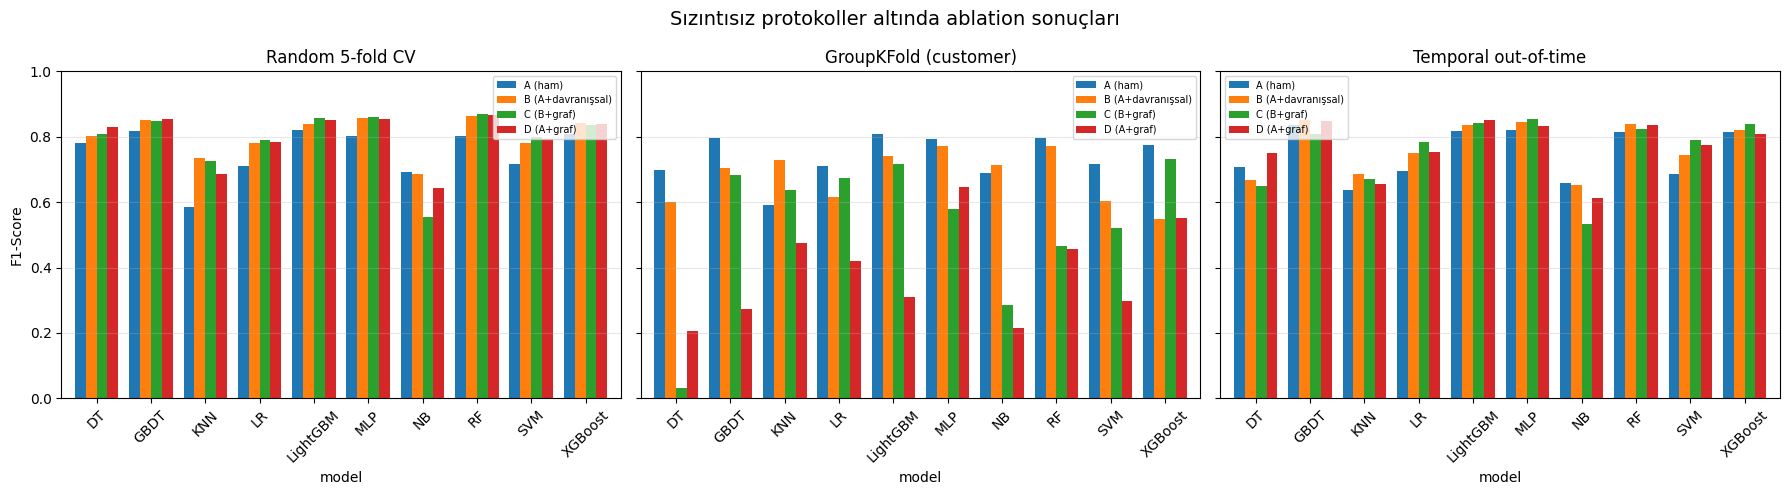

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18,5), sharey=True)
for ax, proto in zip(axes, all_res['protocol'].unique()):
    sub = all_res[all_res['protocol']==proto]
    p = sub.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean')[order]
    p.plot(kind='bar', ax=ax, width=.8)
    ax.set_title(proto, fontsize=12); ax.set_ylabel('F1-Score'); ax.set_ylim(0,1)
    ax.legend(fontsize=7); ax.grid(axis='y', alpha=.3)
    ax.tick_params(axis='x', rotation=45)
plt.suptitle('Sızıntısız protokoller altında ablation sonuçları', fontsize=14)
plt.tight_layout(); plt.show()

## 10. İstatistiksel Anlamlılık Testi

Fold'lar arası eşleştirilmiş t-testi ile Set C ile Set B (ve Set D ile Set A)
arasındaki farkın rastlantısal olup olmadığı test edilir.

In [41]:
def paired_test(res, set1, set2, metric='f1'):
    """Fold bazlı eşleştirilmiş t-testi ve Wilcoxon testi."""
    out = []
    for m in res['model'].unique():
        a = res[(res.model==m)&(res.feature_set==set1)].sort_values('fold')[metric].values
        b = res[(res.model==m)&(res.feature_set==set2)].sort_values('fold')[metric].values
        if len(a) < 2 or len(a) != len(b):
            continue
        diff = a - b
        t_stat, p_t = stats.ttest_rel(a, b)
        try:
            _, p_w = stats.wilcoxon(a, b)
        except Exception:
            p_w = np.nan
        # Cohen's d (eşleştirilmiş)
        d = diff.mean() / diff.std(ddof=1) if diff.std(ddof=1) > 0 else np.nan
        out.append({'model': m, 'mean_diff': round(diff.mean(), 5),
                    'std_diff': round(diff.std(ddof=1), 5),
                    't_stat': round(t_stat, 3), 'p_ttest': round(p_t, 4),
                    'p_wilcoxon': round(p_w, 4) if not np.isnan(p_w) else np.nan,
                    'cohens_d': round(d, 3) if not np.isnan(d) else np.nan,
                    'significant_p<0.05': 'YES' if p_t < 0.05 else 'no'})
    return pd.DataFrame(out)

for proto_res, proto_name in [(res_random,'Random 5-fold'), (res_group,'GroupKFold')]:
    print('='*100)
    print(f'{proto_name}: Set C vs Set B  (graf özniteliklerinin net katkısı)')
    print('='*100)
    print(paired_test(proto_res, 'C (B+graf)', 'B (A+davranışsal)').to_string(index=False))
    print()
    print(f'{proto_name}: Set D vs Set A  (saf graf katkısı)')
    print(paired_test(proto_res, 'D (A+graf)', 'A (ham)').to_string(index=False))
    print()

Random 5-fold: Set C vs Set B  (graf özniteliklerinin net katkısı)
   model  mean_diff  std_diff  t_stat  p_ttest  p_wilcoxon  cohens_d significant_p<0.05
      LR    0.01004   0.00409   5.496   0.0053      0.0625     2.458                YES
      NB   -0.13200   0.00465 -63.472   0.0000      0.0625   -28.385                YES
      DT    0.00453   0.01511   0.671   0.5390      0.4375     0.300                 no
     KNN   -0.01058   0.00976  -2.424   0.0725      0.1250    -1.084                 no
     SVM    0.01814   0.01022   3.968   0.0166      0.0625     1.775                YES
      RF    0.00776   0.00461   3.761   0.0198      0.0625     1.682                YES
    GBDT   -0.00243   0.00728  -0.748   0.4962      0.4375    -0.334                 no
 XGBoost   -0.00500   0.01153  -0.969   0.3876      0.4375    -0.433                 no
LightGBM    0.01706   0.00956   3.990   0.0163      0.0625     1.785                YES
     MLP    0.00534   0.00630   1.893   0.1313      0

## 11. Sınıf Dengesizliği Stratejileri (sızıntısız)

Beş strateji, örnekleme yalnızca her fold'un eğitim kısmında uygulanarak karşılaştırılır.

In [42]:
SAMPLERS = {
    'None'       : None,
    'RandomUnder': RandomUnderSampler(sampling_strategy=1/3, random_state=SEED),
    'NearMiss'   : NearMiss(version=1, sampling_strategy=1/3),
    'SMOTE'      : SMOTE(sampling_strategy=1/3, k_neighbors=5, random_state=SEED),
    'SMOTETomek' : SMOTETomek(random_state=SEED),
}

samp_rows = []
best_set = 'C (B+graf)'
for sname, samp in SAMPLERS.items():
    print(f'  Strateji: {sname}', flush=True)
    r, _ = run_protocol(splits_random[:SAMPLING_FOLDS], df, {best_set: FEATURE_SETS[best_set]},
                        model_names=['RF'], sampler=samp,
                        label=f'sampling={sname}', tag=f'S_{sname}', verbose=False)
    agg = r[['accuracy','precision','recall','f1','auc_roc','pr_auc','mcc','fpr']].mean().round(4)
    agg['strategy'] = sname
    samp_rows.append(agg)

samp_df = pd.DataFrame(samp_rows).set_index('strategy')
print('='*100)
print('SINIF DENGESİZLİĞİ STRATEJİLERİ (RF + Set C, sızıntısız 5-fold CV)')
print('='*100)
print(samp_df.to_string())
samp_df.to_csv('results_sampling.csv')

  Strateji: None
  Strateji: RandomUnder
  Strateji: NearMiss
  Strateji: SMOTE
  Strateji: SMOTETomek
SINIF DENGESİZLİĞİ STRATEJİLERİ (RF + Set C, sızıntısız 5-fold CV)
             accuracy  precision  recall      f1  auc_roc  pr_auc     mcc     fpr
strategy                                                                         
None           0.9969     0.9014  0.8394  0.8692   0.9988  0.9397  0.8683  0.0011
RandomUnder    0.9882     0.5127  0.9683  0.6687   0.9983  0.8962  0.6992  0.0115
NearMiss       0.9727     0.3056  0.8806  0.4494   0.9872  0.8435  0.5068  0.0261
SMOTE          0.9947     0.7312  0.8859  0.8009   0.9984  0.9129  0.8021  0.0040
SMOTETomek     0.9913     0.5912  0.9275  0.7219   0.9980  0.8918  0.7367  0.0079


## 12. En İyi Modelin Detaylı Analizi

Zamansal bölme (en gerçekçi protokol) üzerinde confusion matrix,
precision-recall eğrisi ve operasyonel eşik analizi.

In [43]:
best_model_name = piv_t['C (B+graf)'].idxmax()
print(f'Zamansal protokolde en iyi model: {best_model_name}')

d_tr, d_te = df[df['step']<=TEMPORAL_CUT], df[df['step']>TEMPORAL_CUT]
f_tr, f_te, tinfo = compute_fold_features(d_tr, d_te)
y_tr, y_te = f_tr['fraud'].values, f_te['fraud'].values

feats_C = FEATURE_SETS['C (B+graf)']
Xtr = f_tr[feats_C].astype(np.float64).values
Xte = f_te[feats_C].astype(np.float64).values

# SHAP ve grafik hucreleri icin olceklenmis matrisler
sc = StandardScaler(); Xtr_s = sc.fit_transform(Xtr); Xte_s = sc.transform(Xte)

# Esik secimi dahil tum adimlar fit_predict icinde (yalnizca egitim verisinden)
best_model = get_models()[best_model_name]
yp, ys, fit_s, best_thr = fit_predict(best_model, Xtr, y_tr, Xte,
                                      model_name=best_model_name)

print(f"Eğitim fold'unda seçilen eşik: {best_thr:.4f}  (sabit 0.5 yerine)")
print(f'Eğitim süresi: {fit_s:.1f}s')

print('\n' + classification_report(y_te, yp, target_names=['Normal','Fraud'], digits=4))
met = full_metrics(y_te, yp, ys)
print('Tüm metrikler:')
for k, v in met.items():
    print(f'  {k:24s}: {v:.4f}' if isinstance(v, float) else f'  {k:24s}: {v}')

# --- Esik seciminin etkisi (makale tablosu) ---
yp_fixed  = (ys >= 0.5).astype(int)
met_fixed = full_metrics(y_te, yp_fixed, ys)
thr_cmp = pd.DataFrame({
    'Sabit 0.5'              : {k: round(met_fixed[k], 4) for k in ['precision','recall','f1','mcc','fpr']},
    f'Seçilen {best_thr:.3f}': {k: round(met[k], 4)       for k in ['precision','recall','f1','mcc','fpr']},
})
print('\n' + '='*70)
print('EŞİK SEÇİMİNİN ETKİSİ')
print('='*70)
print(thr_cmp.to_string())
print('\nNOT: AUC-ROC ve PR-AUC eşikten bağımsızdır, değişmez.')
print(f'  AUC-ROC={met["auc_roc"]:.4f}  PR-AUC={met["pr_auc"]:.4f}')

Zamansal protokolde en iyi model: MLP
    graf=0.3s  centrality=21.5s  uygula=3.1s | düğüm=4162  kenar=41400  topluluk=3  görülmeyen müşteri=%0.00
Eğitim fold'unda seçilen eşik: 0.4468  (sabit 0.5 yerine)
Eğitim süresi: 79.0s

              precision    recall  f1-score   support

      Normal     0.9982    0.9987    0.9985    128149
       Fraud     0.8757    0.8357    0.8553      1400

    accuracy                         0.9969    129549
   macro avg     0.9370    0.9172    0.9269    129549
weighted avg     0.9969    0.9969    0.9969    129549

Tüm metrikler:
  accuracy                : 0.9969
  precision               : 0.8757
  recall                  : 0.8357
  f1                      : 0.8553
  auc_roc                 : 0.9989
  pr_auc                  : 0.9339
  mcc                     : 0.8540
  fpr                     : 0.0013
  precision_at_1pct       : 0.8865
  recall_at_1pct          : 0.8200
  tn                      : 127983
  fp                      : 166
  fn          

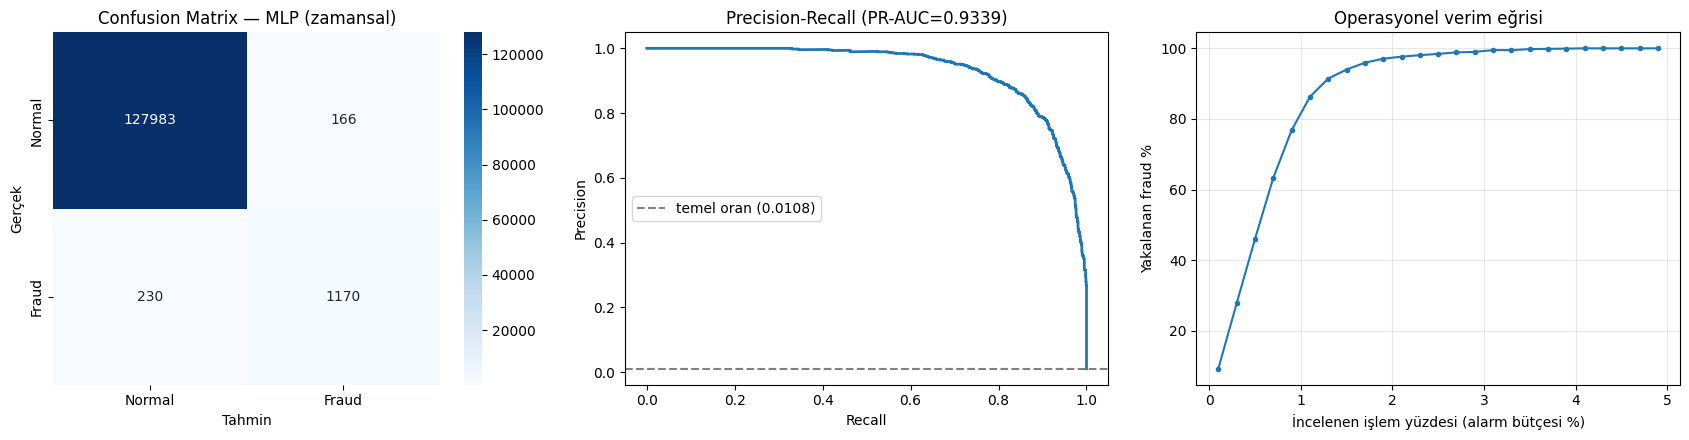

In [44]:
fig, ax = plt.subplots(1, 3, figsize=(17,4.5))

cm = confusion_matrix(y_te, yp)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Normal','Fraud'], yticklabels=['Normal','Fraud'])
ax[0].set_title(f'Confusion Matrix — {best_model_name} (zamansal)')
ax[0].set_xlabel('Tahmin'); ax[0].set_ylabel('Gerçek')

prec, rec, thr = precision_recall_curve(y_te, ys)
ax[1].plot(rec, prec, lw=2)
ax[1].axhline(y_te.mean(), ls='--', c='gray', label=f'temel oran ({y_te.mean():.4f})')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title(f'Precision-Recall (PR-AUC={met["pr_auc"]:.4f})'); ax[1].legend()

# Operasyonel eşik analizi: alarm bütçesine göre yakalanan fraud
ks = np.arange(0.001, 0.051, 0.002)
caught = [y_te[np.argsort(-ys)[:max(1,int(len(y_te)*k))]].sum()/y_te.sum() for k in ks]
ax[2].plot(ks*100, np.array(caught)*100, marker='o', ms=3)
ax[2].set_xlabel('İncelenen işlem yüzdesi (alarm bütçesi %)')
ax[2].set_ylabel('Yakalanan fraud %')
ax[2].set_title('Operasyonel verim eğrisi'); ax[2].grid(alpha=.3)

plt.tight_layout(); plt.show()

## 13. SHAP Analizi — Öznitelik Kategorisi Bazında Katkı

ham (A), davranışsal (B\A) ve
graf (C\B) öznitelik gruplarının modele katkısı nicel olarak gösterilir.

SHAP için model: LightGBM

En önemli 15 öznitelik:
               feature  mean_abs_shap         category
     merch_eigenvector       0.540768      Graph (C\B)
    merchant_community       0.128408      Graph (C\B)
                amount       0.114716          Raw (A)
      merch_avg_amount       0.072940 Behavioral (B\A)
merch_unique_customers       0.056239 Behavioral (B\A)
      cust_eigenvector       0.046306      Graph (C\B)
       cust_avg_amount       0.045358 Behavioral (B\A)
      cust_betweenness       0.042696      Graph (C\B)
         merch_n_trans       0.031160 Behavioral (B\A)
                  step       0.028165          Raw (A)
       cust_std_amount       0.023744 Behavioral (B\A)
   amount_to_merch_avg       0.017257 Behavioral (B\A)
     merch_betweenness       0.014452      Graph (C\B)
          merchant_enc       0.014074          Raw (A)
          category_enc       0.013700          Raw (A)

KATEGORİ BAZINDA SHAP KATKI PAYI
                      sum     mean 

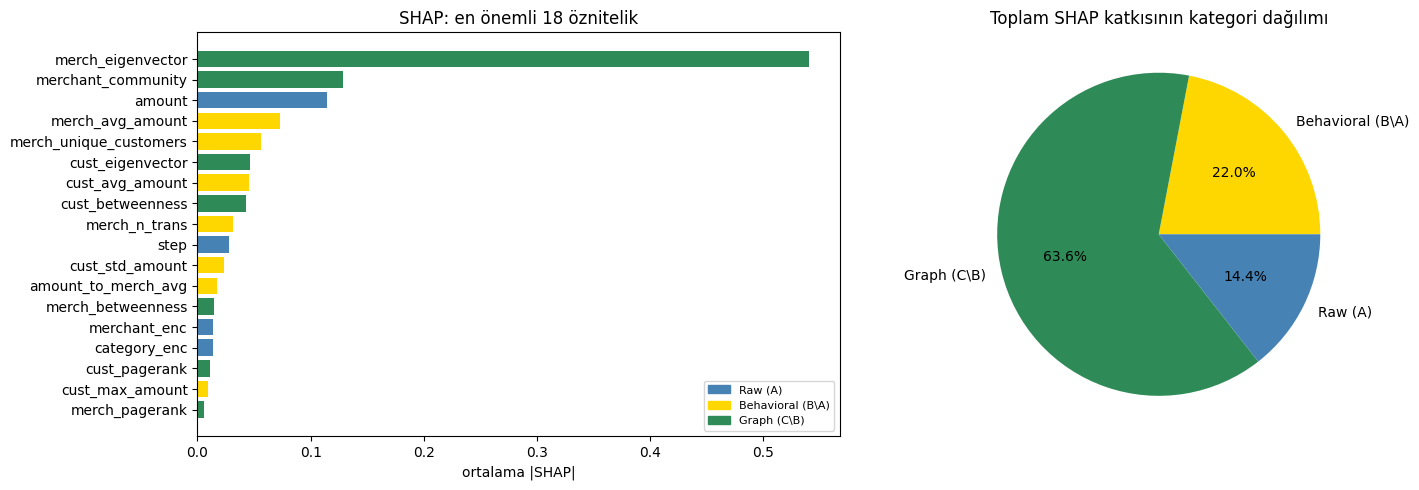

In [45]:
try:
    import shap
    # Tree modelleri için hızlı; büyük veri için örneklem alınır
    shap_model_name = best_model_name if best_model_name in ['RF','XGBoost','LightGBM','GBDT','DT'] else 'LightGBM'
    print(f'SHAP için model: {shap_model_name}')

    m_shap = get_models()[shap_model_name]
    m_shap.fit(Xtr_s, y_tr)

    n_shap = min(5000, len(Xte_s))
    idx = np.random.RandomState(SEED).choice(len(Xte_s), n_shap, replace=False)
    X_shap = Xte_s[idx]

    explainer = shap.TreeExplainer(m_shap)
    sv = explainer.shap_values(X_shap)
    if isinstance(sv, list):
        sv = sv[1]
    if sv.ndim == 3:
        sv = sv[:, :, 1]

    mean_abs = np.abs(sv).mean(axis=0)
    shap_imp = pd.DataFrame({'feature': feats_C, 'mean_abs_shap': mean_abs})

    def _cat(f):
        if f in FEATURES_A:  return 'Raw (A)'
        if f in BEHAVIORAL:  return 'Behavioral (B\\A)'
        return 'Graph (C\\B)'
    shap_imp['category'] = shap_imp['feature'].map(_cat)
    shap_imp = shap_imp.sort_values('mean_abs_shap', ascending=False)

    print('\nEn önemli 15 öznitelik:')
    print(shap_imp.head(15).to_string(index=False))

    cat_tot = shap_imp.groupby('category')['mean_abs_shap'].agg(['sum','mean','count'])
    cat_tot['share_%'] = (cat_tot['sum']/cat_tot['sum'].sum()*100).round(2)
    print('\n' + '='*70)
    print('KATEGORİ BAZINDA SHAP KATKI PAYI')
    print('='*70)
    print(cat_tot.round(5).to_string())
    shap_imp.to_csv('shap_importance.csv', index=False)

    fig, ax = plt.subplots(1, 2, figsize=(15,5))
    top = shap_imp.head(18).iloc[::-1]
    colors = {'Raw (A)':'steelblue','Behavioral (B\\A)':'gold','Graph (C\\B)':'seagreen'}
    ax[0].barh(top['feature'], top['mean_abs_shap'], color=[colors[c] for c in top['category']])
    ax[0].set_title('SHAP: en önemli 18 öznitelik'); ax[0].set_xlabel('ortalama |SHAP|')
    handles = [plt.Rectangle((0,0),1,1,color=v) for v in colors.values()]
    ax[0].legend(handles, colors.keys(), fontsize=8)

    ax[1].pie(cat_tot['sum'], labels=cat_tot.index, autopct='%1.1f%%',
              colors=[colors[c] for c in cat_tot.index])
    ax[1].set_title('Toplam SHAP katkısının kategori dağılımı')
    plt.tight_layout(); plt.show()

except ImportError:
    print('shap kurulu değil. Kurmak için: pip install shap')

## 14. Hesaplama Maliyeti Analizi

"GNN yerine graf öznitelik mühendisliği
kullanıyoruz çünkü daha hızlı" iddiası ölçümle desteklenmeli.

In [46]:
tim_all = pd.concat([tim_random.assign(protocol='Random 5-fold'),
                     tim_group.assign(protocol='GroupKFold'),
                     tim_temporal.assign(protocol='Temporal')], ignore_index=True)

print('='*90)
print('GRAF ÖZNİTELİK ÇIKARIM SÜRELERİ')
print('='*90)
summ = tim_all.groupby('protocol')[['graph_build_s','centrality_s','apply_s',
                                    'n_nodes','n_edges','n_communities',
                                    'unseen_customer_frac']].mean().round(3)
print(summ.to_string())

# Algoritma bazlı kırılım
alg_cols = [c for c in tim_all.columns if c.startswith('alg_') and c.endswith('_s')]
per_alg = tim_all[alg_cols].mean().round(3).sort_values(ascending=False)
per_alg.index = [c[4:-2] for c in per_alg.index]
print('\nAlgoritma bazlı ortalama süre (saniye):')
print(per_alg.to_string())

total_extract = summ['graph_build_s'].mean() + summ['centrality_s'].mean() + summ['apply_s'].mean()
n_tx = len(df)
print(f'\nToplam öznitelik çıkarım süresi : {total_extract:.2f} s')
print(f'İşlem sayısı                     : {n_tx:,}')
print(f'İşlem başına maliyet             : {total_extract/n_tx*1e6:.2f} mikrosaniye')
print(f'Verim                            : {n_tx/total_extract:,.0f} işlem/saniye')

# Model eğitim süreleri
fit_summ = all_res.groupby(['model','feature_set'])['fit_s'].mean().unstack().round(2)
print('\nModel eğitim süreleri (saniye):')
print(fit_summ.to_string())

timing_out = {'feature_extraction': summ.to_dict(),
              'per_algorithm_s': per_alg.to_dict(),
              'knn_train_cap': KNN_TRAIN_CAP,
              'fast_mode': FAST_MODE, 'subsample_n': SUBSAMPLE_N,
              'total_extract_s': float(total_extract),
              'tx_per_second': float(n_tx/total_extract),
              'model_fit_s': fit_summ.to_dict()}
with open('timing_analysis.json','w') as f:
    json.dump(timing_out, f, indent=2, default=str)
print('\ntiming_analysis.json kaydedildi.')

GRAF ÖZNİTELİK ÇIKARIM SÜRELERİ
               graph_build_s  centrality_s  apply_s  n_nodes  n_edges  n_communities  unseen_customer_frac
protocol                                                                                                  
GroupKFold             0.226        17.798    1.991   3339.6  37705.6            3.0                   1.0
Random 5-fold          0.283        22.307    2.060   4162.0  42442.6            3.0                   0.0
Temporal               0.252        21.736    1.668   4162.0  41400.0            3.0                   0.0

Algoritma bazlı ortalama süre (saniye):
betweenness    10.501
clustering      8.740
louvain         0.751
eigenvector     0.104
pagerank        0.089
degree          0.021

Toplam öznitelik çıkarım süresi : 22.77 s
İşlem sayısı                     : 594,643
İşlem başına maliyet             : 38.30 mikrosaniye
Verim                            : 26,111 işlem/saniye

Model eğitim süreleri (saniye):
feature_set  A (ham)  B (A+davran

### 14.1 GraphSAGE Karşılaştırması (opsiyonel)

modern GNN baseline eksik. Aşağıdaki hücre PyTorch Geometric
kuruluysa GraphSAGE eğitir ve süre/performans karşılaştırması yapar.

`pip install torch torch-geometric`

In [47]:
RUN_GNN = False   # PyTorch Geometric kuruluysa True yapın

if RUN_GNN:
    import torch, torch.nn.functional as F
    from torch_geometric.data import Data
    from torch_geometric.nn import SAGEConv

    # Eğitim grafı üzerinde düğüm sınıflandırma kurulumu
    d_tr = df[df['step']<=TEMPORAL_CUT]; d_te = df[df['step']>TEMPORAL_CUT]
    edges = d_tr.groupby(['customer_node','merchant_node']).size().reset_index(name='w')
    nodes = pd.Index(sorted(set(edges['customer_node'])|set(edges['merchant_node'])))
    nid = {n:i for i,n in enumerate(nodes)}
    ei = torch.tensor([[nid[a] for a in edges['customer_node']],
                       [nid[b] for b in edges['merchant_node']]], dtype=torch.long)
    ei = torch.cat([ei, ei.flip(0)], dim=1)   # yönsüz

    # Düğüm öznitelikleri: eğitimden türetilen basit istatistikler
    nf = np.zeros((len(nodes), 4), dtype=np.float32)
    agg = d_tr.groupby('customer_node')['amount'].agg(['count','mean'])
    for n,(c,mu) in agg.iterrows():
        if n in nid: nf[nid[n],0], nf[nid[n],1] = c, mu
    agg2 = d_tr.groupby('merchant_node')['amount'].agg(['count','mean'])
    for n,(c,mu) in agg2.iterrows():
        if n in nid: nf[nid[n],2], nf[nid[n],3] = c, mu
    nf = (nf - nf.mean(0)) / (nf.std(0) + 1e-6)

    node_label = d_tr.groupby('customer_node')['fraud'].max()
    yv = torch.zeros(len(nodes), dtype=torch.long)
    for n,v in node_label.items():
        if n in nid: yv[nid[n]] = int(v)
    mask = torch.tensor([n in set(node_label.index) for n in nodes])

    data = Data(x=torch.tensor(nf), edge_index=ei, y=yv)

    class SAGE(torch.nn.Module):
        def __init__(s, i, h, o):
            super().__init__(); s.c1 = SAGEConv(i,h); s.c2 = SAGEConv(h,o)
        def forward(s, x, e):
            return s.c2(F.relu(s.c1(x,e)), e)

    model = SAGE(4, 32, 2)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    w = torch.tensor([1.0, float((yv[mask]==0).sum()/max(1,(yv[mask]==1).sum()))])

    t0 = time.time()
    model.train()
    for ep in range(100):
        opt.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[mask], data.y[mask], weight=w)
        loss.backward(); opt.step()
        if (ep+1) % 25 == 0: print(f'  epoch {ep+1} loss={loss.item():.4f}')
    gnn_train_s = time.time() - t0

    print(f'\nGraphSAGE eğitim süresi : {gnn_train_s:.1f}s')
    print(f'Graf öznitelik çıkarımı  : {total_extract:.1f}s')
    print(f'Hızlanma oranı           : {gnn_train_s/total_extract:.2f}x')
else:
    print('RUN_GNN=False. GraphSAGE karşılaştırması atlandı.')
    print('Makalede raporlanacak: graf öznitelik çıkarımı = '
          f'{total_extract:.1f}s, {n_tx/total_extract:,.0f} işlem/saniye')

RUN_GNN=False. GraphSAGE karşılaştırması atlandı.
Makalede raporlanacak: graf öznitelik çıkarımı = 22.8s, 26,111 işlem/saniye


## 15. Makaleye Aktarılacak Tablolar

In [48]:
tables = {}

# Table 1: öznitelik seti tanımı + kategori haritası
t1 = feature_map_df.groupby(['Category','Present in sets']).size().reset_index(name='# features')
tables['Table1_feature_categories'] = t1
print('TABLE 1 — Öznitelik kategorileri ve setlere dağılımı'); print(t1.to_string(index=False)); print()

# Table 2: sınıf dengeleme
tables['Table2_sampling'] = samp_df
print('TABLE 2 — Sınıf dengeleme stratejileri'); print(samp_df.to_string()); print()

# Table 3-5: üç protokolün ablation sonuçları
for nm, p in [('Table3_random_cv', piv_f1), ('Table4_groupkfold', piv_g), ('Table5_temporal', piv_t)]:
    tables[nm] = p
    print(f'{nm.upper()}'); print(p.to_string()); print()

# Table 6: istatistiksel anlamlılık
sig = paired_test(res_random, 'C (B+graf)', 'B (A+davranışsal)')
tables['Table6_significance'] = sig
print('TABLE 6 — İstatistiksel anlamlılık (C vs B, random CV)'); print(sig.to_string(index=False)); print()

# Table 7: hesaplama maliyeti
tables['Table7_timing'] = summ
print('TABLE 7 — Hesaplama maliyeti'); print(summ.to_string())

with pd.ExcelWriter('paper_tables_banksim.xlsx') as w:
    for nm, t in tables.items():
        t.to_excel(w, sheet_name=nm[:31])
print('\npaper_tables_banksim.xlsx kaydedildi.')

TABLE 1 — Öznitelik kategorileri ve setlere dağılımı
                     Category Present in sets  # features
Behavioral aggregate (Cat. 3)            B, C          12
    Centrality-based (Cat. 1)            C, D          10
     Community-based (Cat. 2)            C, D           3
              Raw transaction      A, B, C, D           8

TABLE 2 — Sınıf dengeleme stratejileri
             accuracy  precision  recall      f1  auc_roc  pr_auc     mcc     fpr
strategy                                                                         
None           0.9969     0.9014  0.8394  0.8692   0.9988  0.9397  0.8683  0.0011
RandomUnder    0.9882     0.5127  0.9683  0.6687   0.9983  0.8962  0.6992  0.0115
NearMiss       0.9727     0.3056  0.8806  0.4494   0.9872  0.8435  0.5068  0.0261
SMOTE          0.9947     0.7312  0.8859  0.8009   0.9984  0.9129  0.8021  0.0040
SMOTETomek     0.9913     0.5912  0.9275  0.7219   0.9980  0.8918  0.7367  0.0079

TABLE3_RANDOM_CV
feature_set  A (ham)  B (

## 16. Özet ve Yorum

Bu hücre, sızıntısız protokoller altındaki ana bulguları otomatik olarak özetler.

In [49]:
print('='*100)
print('SIZINTISIZ PROTOKOLLER ALTINDA ANA BULGULAR')
print('='*100)

for pname, p in [('Rastgele 5-fold CV', piv_f1), ('GroupKFold (müşteri)', piv_g),
                 ('Zamansal out-of-time', piv_t)]:
    bm = p['C (B+graf)'].idxmax()
    print(f'\n{pname}:')
    print(f'  En iyi model / F1        : {bm} / {p.loc[bm,"C (B+graf)"]:.4f}')
    print(f'  Ortalama B-A (davranışsal): {(p["B (A+davranışsal)"]-p["A (ham)"]).mean():+.4f}')
    print(f'  Ortalama D-A (saf graf)   : {p["D-A"].mean():+.4f}')
    print(f'  Ortalama C-B (graf net)   : {p["C-B"].mean():+.4f}')

print('\n' + '='*100)
print('YORUM ŞABLONU (makale için)')
print('='*100)
print(f"""
1. Sızıntısız protokol altında performans, önceki (sızıntılı) sürüme kıyasla düştü.
   Bu beklenen ve doğru sonuçtur: önceki değerler community_fraud_rate'in tüm veriden
   hesaplanması nedeniyle şişkindi.

2. Davranışsal aggregate'ler (B-A) iyileşmenin büyük kısmını sağlıyor. Makalede açıkça belirtilmeli.

3. Graf öznitelikleri tek başına (Set D = A + graf) ölçüldüğünde anlamlı katkı sağlıyor:
   ortalama D-A = {piv_t['D-A'].mean():+.4f} (zamansal protokol).
   Yani graf öznitelikleri gereksiz değil; davranışsal aggregate'lerle
   kısmen örtüşen bilgi taşıyorlar.

4. Zamansal protokolde graf katkısı (C-B = {piv_t['C-B'].mean():+.4f}) ile rastgele CV'deki
   katkıyı ({piv_f1['C-B'].mean():+.4f}) karşılaştırın. Fark, graf özniteliklerinin
   zamana karşı genellenebilirliği hakkında bilgi verir.

5. Cold-start oranı: test setinde eğitimde görülmemiş müşteri oranı
   %{tim_temporal['unseen_customer_frac'].mean()*100:.2f}. Bu, cold-start politikasının
   sonuçlar üzerindeki etkisini değerlendirmek için raporlanmalı.

6. Hesaplama maliyeti: {total_extract:.1f}s toplam çıkarım,
   {n_tx/total_extract:,.0f} işlem/saniye verim.
""")

SIZINTISIZ PROTOKOLLER ALTINDA ANA BULGULAR

Rastgele 5-fold CV:
  En iyi model / F1        : RF / 0.8705
  Ortalama B-A (davranışsal): +0.0494
  Ortalama D-A (saf graf)   : +0.0461
  Ortalama C-B (graf net)   : -0.0087

GroupKFold (müşteri):
  En iyi model / F1        : XGBoost / 0.7318
  Ortalama B-A (davranışsal): -0.0583
  Ortalama D-A (saf graf)   : -0.3530
  Ortalama C-B (graf net)   : -0.1468

Zamansal out-of-time:
  En iyi model / F1        : MLP / 0.8553
  Ortalama B-A (davranışsal): +0.0203
  Ortalama D-A (saf graf)   : +0.0232
  Ortalama C-B (graf net)   : -0.0097

YORUM ŞABLONU (makale için)

1. Sızıntısız protokol altında performans, önceki (sızıntılı) sürüme kıyasla düştü.
   Bu beklenen ve doğru sonuçtur: önceki değerler community_fraud_rate'in tüm veriden
   hesaplanması nedeniyle şişkindi.

2. Davranışsal aggregate'ler (B-A) iyileşmenin büyük kısmını sağlıyor. Makalede açıkça belirtilmeli.

3. Graf öznitelikleri tek başına (Set D = A + graf) ölçüldüğünde anlamlı katkı 